# Minimum and Maximum Window Selection

This notebook estimates a **minimum stable window size** for each time-series family. It tests increasing candidate windows by splitting each window into two halves and applying the Wilcoxon signed-rank test. The first size for which at least 80% of tested positions are considered stable is selected for each stream.

The analysis covers the all datasets. It summarizes the per-stream estimates, saves the per-family 95th-percentile minimum and corresponding maximum window (`2 × minimum`) to [`stable_windows.csv`](../../stable_windows.csv), and visualizes the results.

**Main settings:** first 1,500 samples per stream; candidate windows from 200 to 1,000 in steps of 20; stability threshold `p ≥ 0.05`; at least 80% stable positions.

# Imports

In [1]:
from pathlib import Path as _Path
import os as _os

for _candidate in (_Path.cwd(), *_Path.cwd().parents):
    if (_candidate / "KALEIDO_multi_instance.py").is_file() and (_candidate / "stable_windows.csv").is_file():
        _code_dir = _candidate
        break
    _nested = _candidate / "results_all_in_one_code"
    if (_nested / "KALEIDO_multi_instance.py").is_file() and (_nested / "stable_windows.csv").is_file():
        _code_dir = _nested
        break
else:
    raise FileNotFoundError("Could not locate results_all_in_one_code; start this notebook inside the repository")

_os.chdir(_code_dir)
(_code_dir / "figures").mkdir(exist_ok=True)
(_code_dir / "example_runs").mkdir(exist_ok=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
import csv
import warnings
from scipy.stats import wilcoxon
from joblib import Parallel, delayed



# Plot style

In [2]:
sns.set_style("whitegrid")
colors = {
    'AR4_linear_1':              '#3266ad',
    'AR4_nonlinear_1':           '#185FA5',
    'random_noisy':              '#639922',
    'random_easy':               '#3B6D11',
    'rolling_mean':              '#7F77DD',
    'friedman_5_drifts':         '#BA7517',
    'friedman_2_drifts':         '#EF9F27',
    'friedman_no_drifts':        '#FAC775',
    'infocom_5G_add_hour':       '#D85A30',
    'infocom_4G_add_hour':       '#993C1D',
    'infocom_5G_add_hour_trend': '#E24B4A',
    'infocom_4G_add_hour_trend': '#A32D2D',
}

# Functions

In [3]:
def load_variable_column_csv(file_path, delimiter=','):
    # The max column count a line in the file could have
    largest_column_count = 0

    # Loop the data lines
    with open(file_path, 'r') as temp_f:
        # Read the lines
        lines = temp_f.readlines()

        for l in lines:
            # Count the column count for the current line
            column_count = len(l.split(delimiter)) + 1
            
            # Set the new most column count
            largest_column_count = column_count if largest_column_count < column_count else largest_column_count

    # Generate column names (will be 0, 1, 2, ..., largest_column_count - 1)
    column_names = [i for i in range(0, largest_column_count)]

    # Read csv
    return pd.read_csv(file_path, header=None, delimiter=delimiter, names=column_names)

# Time series load

In [4]:
x_AR4_linear_1 = load_variable_column_csv('datasets/synthetic_linear_nonlinear_datasets/time_series_linear_abrupt_100.csv')
data_streams_AR4_linear_1 = x_AR4_linear_1.values
labels_AR4_linear_1 = load_variable_column_csv('datasets/synthetic_linear_nonlinear_datasets/drift_labels_linear_abrupt_100.csv').values

uncertainties = np.load('../uncertainty_our_results/uncertainties_TS.npy')
data_streams_rolling_mean = [uncertainties, pd.Series(uncertainties).rolling(window = 10).mean().values,
                pd.Series(uncertainties).rolling(window = 20).mean().values,
                pd.Series(uncertainties).rolling(window = 30).mean().values,
                pd.Series(uncertainties).rolling(window = 40).mean().values,
                pd.Series(uncertainties).rolling(window = 50).mean().values,
                pd.Series(uncertainties).rolling(window = 60).mean().values,
                pd.Series(uncertainties).rolling(window = 70).mean().values,
                pd.Series(uncertainties).rolling(window = 80).mean().values,
                pd.Series(uncertainties).rolling(window = 90).mean().values,
                pd.Series(uncertainties).rolling(window = 100).mean().values
                ]
x_rolling_mean = data_streams_rolling_mean
labels_rolling_mean = pd.DataFrame([[2000, 4500, 13000]] * len(data_streams_rolling_mean)).values

data_friedman = pd.read_csv('../uncertainty-drift-detection/01_Artificial_DataSets/friedman_with_2_abrupt_drift.csv')
data_streams_friedman = [data_friedman['y_1']]
x_friedman = data_streams_friedman
labels_friedman = pd.DataFrame([[2000, 3000, 5000, 7500, 16000]] * len(data_streams_friedman)).values

data_friedman_5_drifts = pd.read_csv('../uncertainty-drift-detection/01_Artificial_DataSets/friedman_with_2_abrupt_drift.csv')
data_streams_friedman_5_drifts = [data_friedman_5_drifts['x1'], data_friedman_5_drifts['x3'], data_friedman_5_drifts['x5'], 
                                  data_friedman_5_drifts['y_1'], data_friedman_5_drifts['y_org']]
x_friedman_5_drifts = data_streams_friedman_5_drifts
labels_friedman_5_drifts = pd.DataFrame([[2000, 3000, 5000, 7500, 16000]] * len(data_streams_friedman_5_drifts)).values

data_friedman_2_drifts = pd.read_csv('../uncertainty-drift-detection/01_Artificial_DataSets/friedman_with_2_abrupt_drift.csv')
data_streams_friedman_2_drifts = [data_friedman_2_drifts['x7'], data_friedman_2_drifts['x9'], data_friedman_2_drifts['x10']]
x_friedman_2_drifts = data_streams_friedman_2_drifts
labels_friedman_2_drifts = pd.DataFrame([[10000, 12000]] * len(data_streams_friedman_2_drifts)).values

data_friedman_no_drifts = pd.read_csv('../uncertainty-drift-detection/01_Artificial_DataSets/friedman_with_2_abrupt_drift.csv')
data_streams_friedman_no_drifts = [data_friedman_no_drifts['x2'], data_friedman_no_drifts['x4'], 
                                   data_friedman_no_drifts['x6'], data_friedman_no_drifts['x8']]
x_friedman_no_drifts = data_streams_friedman_no_drifts
labels_friedman_no_drifts = pd.DataFrame([[10000]] * len(data_streams_friedman_no_drifts)).values # the label here is only for stat

x_random_noisy = load_variable_column_csv('datasets/synthetic_random_datasets/time_series_random_noisy_100.csv')
data_streams_random_noisy = x_random_noisy.values
labels_random_noisy = load_variable_column_csv('datasets/synthetic_random_datasets/drift_labels_random_noisy_100.csv').values

x_random_easy = load_variable_column_csv('datasets/synthetic_random_datasets/time_series_random_simple_100.csv')
data_streams_random_easy = x_random_easy.values
labels_random_easy = load_variable_column_csv('datasets/synthetic_random_datasets/drift_labels_random_simple_100.csv').values
               
x_AR4_nonlinear_1 = load_variable_column_csv('datasets/synthetic_linear_nonlinear_datasets/time_series_nonlinear_abrupt_100.csv')
data_streams_AR4_nonlinear_1 = x_AR4_nonlinear_1.values
labels_AR4_nonlinear_1 = load_variable_column_csv('datasets/synthetic_linear_nonlinear_datasets/drift_labels_nonlinear_abrupt_100.csv').values


x_infocom_5G_add_hour = load_variable_column_csv('datasets/INFOCOM/ran_updates_event_5G addition_hour_granularity.csv')
data_streams_infocom_5G_add_hour = x_infocom_5G_add_hour.values
labels_infocom_5G_add_hour = load_variable_column_csv('datasets/INFOCOM/drift_labels_ran_updates_event_5G addition_hour_granularity.csv').values

x_infocom_4G_add_hour = load_variable_column_csv('datasets/INFOCOM/ran_updates_event_4G addition_hour_granularity.csv')
data_streams_infocom_4G_add_hour = x_infocom_4G_add_hour.values
labels_infocom_4G_add_hour = load_variable_column_csv('datasets/INFOCOM/drift_labels_ran_updates_event_4G addition_hour_granularity.csv').values

x_infocom_5G_add_hour_trend = load_variable_column_csv('datasets/INFOCOM/ran_updates_event_5G addition_hour_granularity_trend.csv')
data_streams_infocom_5G_add_hour_trend = x_infocom_5G_add_hour_trend.values
labels_infocom_5G_add_hour_trend = load_variable_column_csv('datasets/INFOCOM/drift_labels_ran_updates_event_5G addition_hour_granularity.csv').values

x_infocom_4G_add_hour_trend = load_variable_column_csv('datasets/INFOCOM/ran_updates_event_4G addition_hour_granularity_trend.csv')
data_streams_infocom_4G_add_hour_trend = x_infocom_4G_add_hour_trend.values
labels_infocom_4G_add_hour_trend = load_variable_column_csv('datasets/INFOCOM/drift_labels_ran_updates_event_4G addition_hour_granularity.csv').values


# Min window analysis

## Parameters

In [5]:
cut_of_stream = 1500
step_size = 20
min_window_size = 200
max_floor = 1001
stable_frac_value = 0.8 # higher stable_frac = stricter, so streams need more of their positions to look stationary before a window "passes" → fewer families floor at 100, more separation.

## Wilcoxon signed-rank test: Smallest window size over which the stream looks statistically stationary

For each stream, drop NaNs and analyze at most the first 1,500 samples. Test candidate window sizes from 200 to 1,000 in steps of 20. At each position, split the window into equal halves and use the Wilcoxon signed-rank test; a p-value of at least 0.05 counts as stable. The first window size with at least 80% stable positions is selected. If none passes, the stream receives NaN.

In [6]:
def process_single_stream(stream, window_range, p_thresh, stable_frac):
    stream = np.array(stream, dtype=float)
    stream = stream[~np.isnan(stream)]
    stream = stream[:cut_of_stream]
    found = np.nan

    for w in window_range:
        if w > len(stream):
            break
        half = w // 2
        step = max(half, 50)
        n_stable = 0
        n_tested = 0
        total_positions = len(range(0, len(stream) - w, step))

        for start in range(0, len(stream) - w, step):
            left  = stream[start        : start + half]
            right = stream[start + half : start + w]

            n = min(len(left), len(right))
            left, right = left[:n], right[:n]

            if n < 10:
                continue

            if np.all(left == right):
                n_tested += 1
                n_stable += 1
            else:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    try:
                        _, p = wilcoxon(left, right)
                        n_tested += 1
                        if p >= p_thresh:
                            n_stable += 1
                    except Exception:
                        continue

            # ── early stop ────────────────────────────────────────
            positions_remaining = total_positions - n_tested  # approximate, but consistent
            if n_tested > 0 and (n_stable / n_tested) >= stable_frac:
                break  # already won
            if n_tested > 0 and (n_stable + positions_remaining) / (n_tested + positions_remaining) < stable_frac:
                break  # already lost
            # ─────────────────────────────────────────────────────

        if n_tested > 0 and (n_stable / n_tested) >= stable_frac:
            found = w
            break

    return found


def find_min_stable_window(data_streams, window_range=range(min_window_size, max_floor, step_size), p_thresh=0.05, n_jobs=-1):
    results = Parallel(n_jobs=n_jobs, verbose=1)(
        delayed(process_single_stream)(stream, window_range, p_thresh, stable_frac=stable_frac_value)
        for stream in data_streams
    )
    return results


# ── compute for each time series ──────────────────────────────────────────────

ts_windows = {
    'AR4_linear_1':              find_min_stable_window(data_streams_AR4_linear_1),
    'AR4_nonlinear_1':           find_min_stable_window(data_streams_AR4_nonlinear_1),
    'random_noisy':              find_min_stable_window(data_streams_random_noisy),
    'random_easy':               find_min_stable_window(data_streams_random_easy),
    'rolling_mean':              find_min_stable_window(data_streams_rolling_mean),
    'friedman_5_drifts':         find_min_stable_window(data_streams_friedman_5_drifts),
    'friedman_2_drifts':         find_min_stable_window(data_streams_friedman_2_drifts),
    'friedman_no_drifts':        find_min_stable_window(data_streams_friedman_no_drifts),
    'infocom_5G_add_hour':       find_min_stable_window(data_streams_infocom_5G_add_hour),
    'infocom_4G_add_hour':       find_min_stable_window(data_streams_infocom_4G_add_hour),
    'infocom_5G_add_hour_trend': find_min_stable_window(data_streams_infocom_5G_add_hour_trend),
    'infocom_4G_add_hour_trend': find_min_stable_window(data_streams_infocom_4G_add_hour_trend),
}

for ts, wins in ts_windows.items():
    arr = np.array(wins, dtype=float)
    print(f"{ts:35s}  median={np.nanmedian(arr):.0f}  mean={np.nanmean(arr):.0f} p95={np.nanpercentile(arr, 95):.0f} nan={np.isnan(arr).sum()}/{len(arr)}")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 96 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 out of 100 | elapsed:    7.2s remaining:  1.1min
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    8.5s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 96 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 out of 100 | elapsed:    0.0s remaining:    0.3s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    0.2s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 96 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 out of 100 | elapsed:    0.0s remaining:    0.3s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    0.2s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 96 concurrent workers.
[Parallel(n_jobs=-1)]: Done  10 out of 100 | elapsed:    0.0s remaining:    0.4s
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:    0.2s finished
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 96 concurrent workers.
[Parall

AR4_linear_1                         median=300  mean=362 p95=670 nan=29/100
AR4_nonlinear_1                      median=200  mean=295 p95=680 nan=8/100
random_noisy                         median=200  mean=200 p95=200 nan=0/100
random_easy                          median=200  mean=200 p95=200 nan=0/100
rolling_mean                         median=540  mean=507 p95=560 nan=0/11
friedman_5_drifts                    median=200  mean=200 p95=200 nan=0/5
friedman_2_drifts                    median=200  mean=200 p95=200 nan=0/3
friedman_no_drifts                   median=200  mean=200 p95=200 nan=0/4
infocom_5G_add_hour                  median=200  mean=202 p95=220 nan=1/50
infocom_4G_add_hour                  median=200  mean=206 p95=242 nan=0/50
infocom_5G_add_hour_trend            median=260  mean=353 p95=934 nan=6/50
infocom_4G_add_hour_trend            median=260  mean=328 p95=596 nan=7/50


[Parallel(n_jobs=-1)]: Done  50 out of  50 | elapsed:    0.1s finished


In [7]:
for ts, wins in ts_windows.items():
    arr = np.array(wins, dtype=float)
    print(f"{ts:35s}   min window (p95)={np.nanpercentile(arr, 95):.0f} max window={np.nanpercentile(arr, 95)*2:.0f}")

AR4_linear_1                          min window (p95)=670 max window=1340
AR4_nonlinear_1                       min window (p95)=680 max window=1360
random_noisy                          min window (p95)=200 max window=400
random_easy                           min window (p95)=200 max window=400
rolling_mean                          min window (p95)=560 max window=1120
friedman_5_drifts                     min window (p95)=200 max window=400
friedman_2_drifts                     min window (p95)=200 max window=400
friedman_no_drifts                    min window (p95)=200 max window=400
infocom_5G_add_hour                   min window (p95)=220 max window=440
infocom_4G_add_hour                   min window (p95)=242 max window=484
infocom_5G_add_hour_trend             min window (p95)=934 max window=1868
infocom_4G_add_hour_trend             min window (p95)=596 max window=1192


## Save windows

In [8]:
with open("stable_windows.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["time_series", "min_window_p95", "max_window"])
    for ts, wins in ts_windows.items():
        arr = np.array(wins, dtype=float)
        p95 = np.nanpercentile(arr, 95)
        w.writerow([ts, f"{p95:.0f}", f"{p95*2:.0f}"])

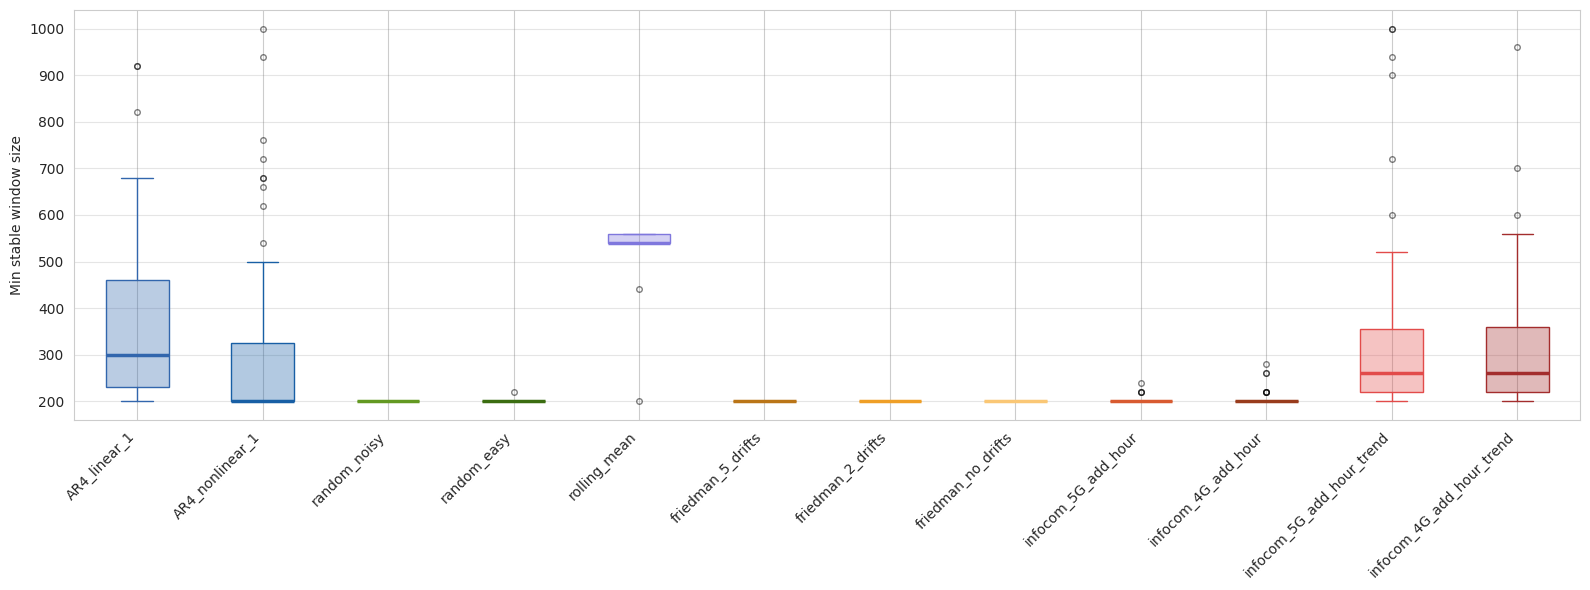

In [9]:
fig, ax = plt.subplots(figsize=(16, 6))

for i, (ts, wins) in enumerate(ts_windows.items()):
    arr = np.array(wins, dtype=float)
    clean = arr[~np.isnan(arr)]
    color = colors[ts]
    if len(clean) > 0:
        ax.boxplot(
            clean,
            positions=[i],
            widths=0.5,
            patch_artist=True,
            boxprops=dict(facecolor=color + '55', color=color),
            medianprops=dict(color=color, linewidth=2.5),
            whiskerprops=dict(color=color),
            capprops=dict(color=color),
            flierprops=dict(marker='o', color=color, markersize=4, alpha=0.5),
        )

ax.set_xticks(range(len(ts_windows)))
ax.set_xticklabels(list(ts_windows.keys()), rotation=45, ha='right', fontsize=10)
ax.set_ylabel('Min stable window size')
# ax.set_ylim(80, 520)
ax.yaxis.grid(True, color='gray', alpha=0.2)
ax.set_axisbelow(True)

legend_handles = [
    mpatches.Patch(facecolor=color + '55', edgecolor=color, label=ts.replace('_', ' '))
    for ts, color in colors.items()
]
# ax.legend(handles=legend_handles, loc='upper left', fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

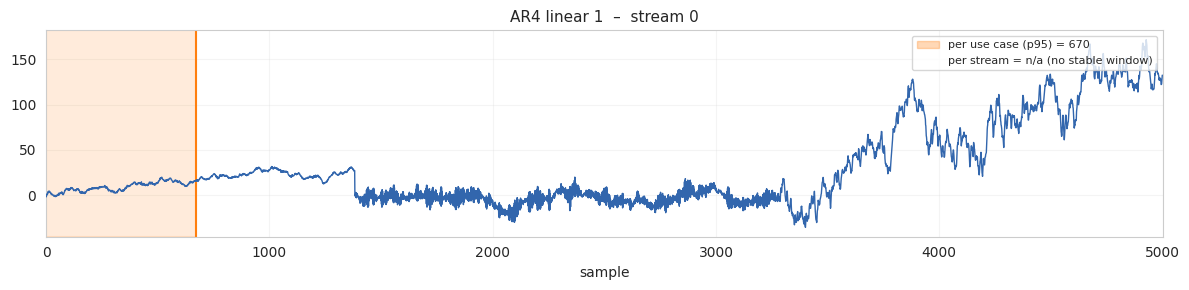

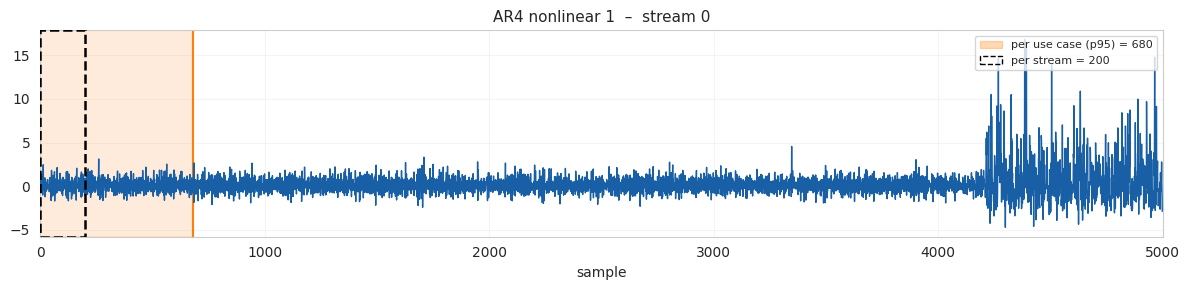

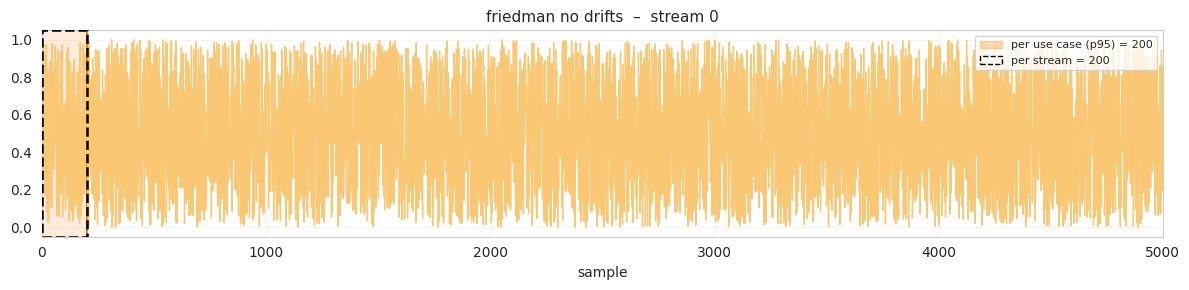

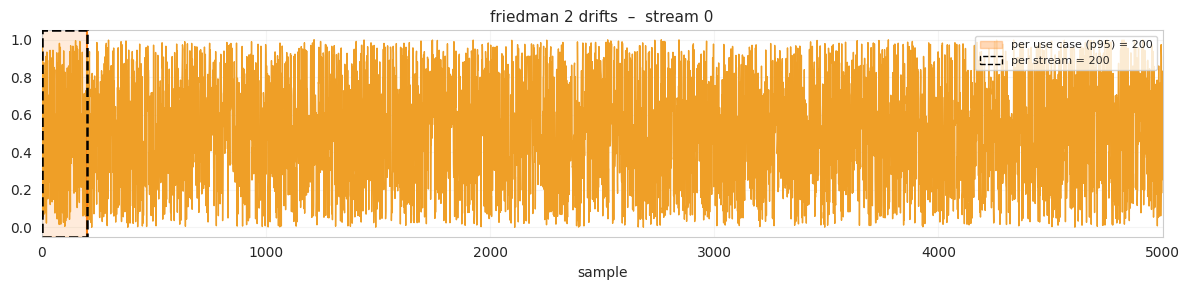

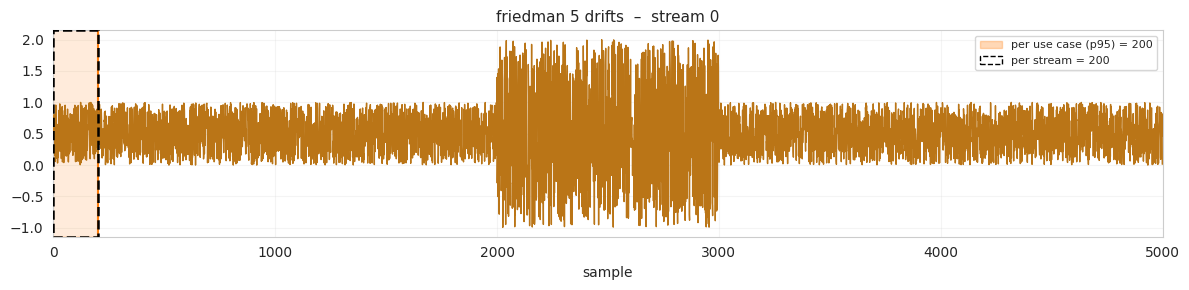

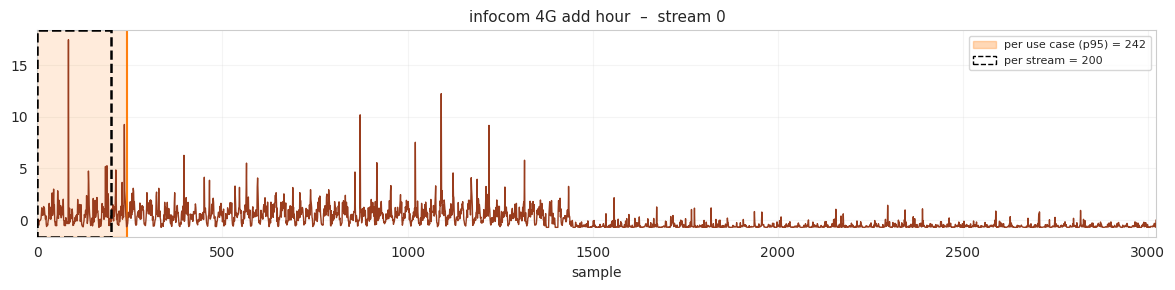

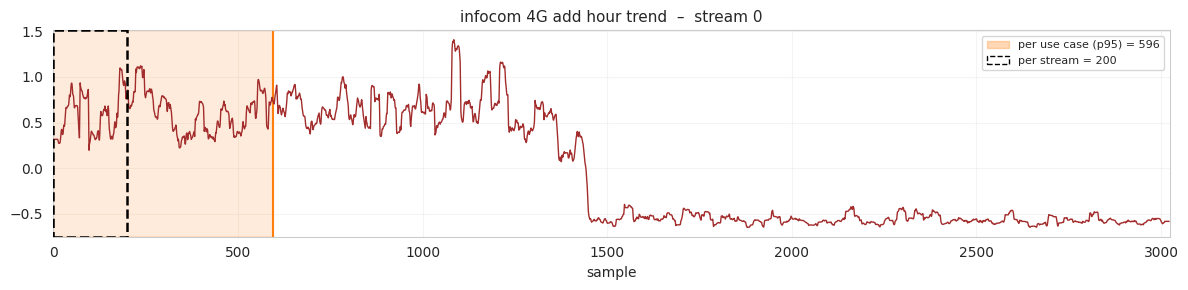

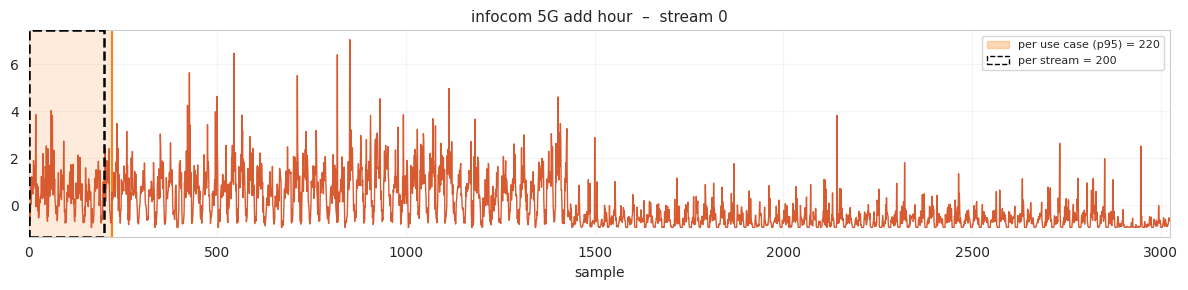

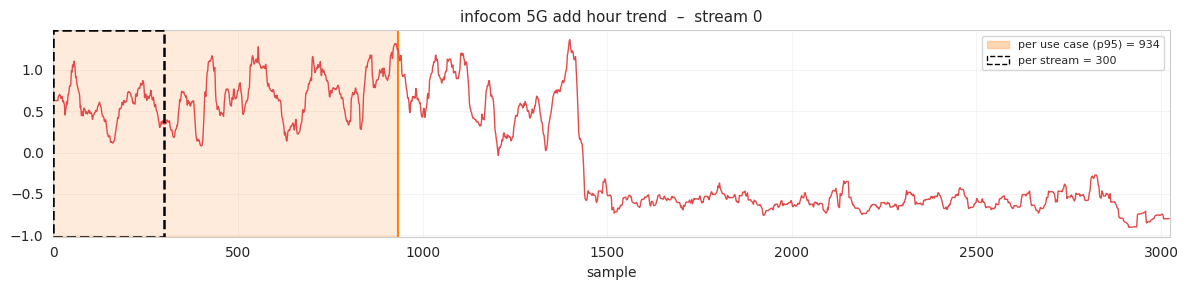

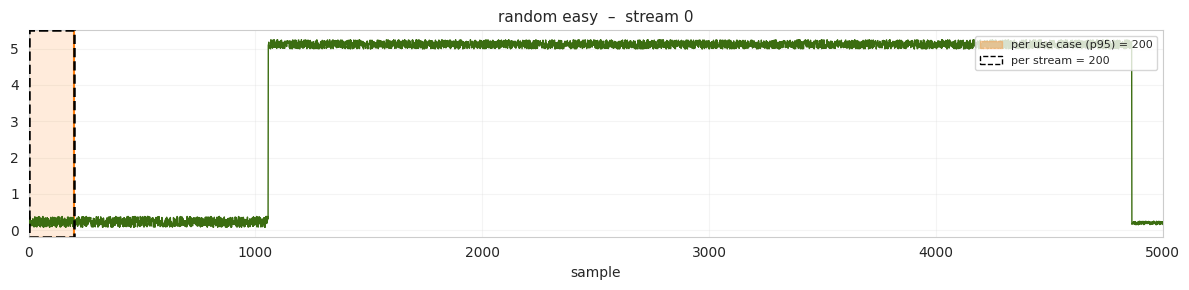

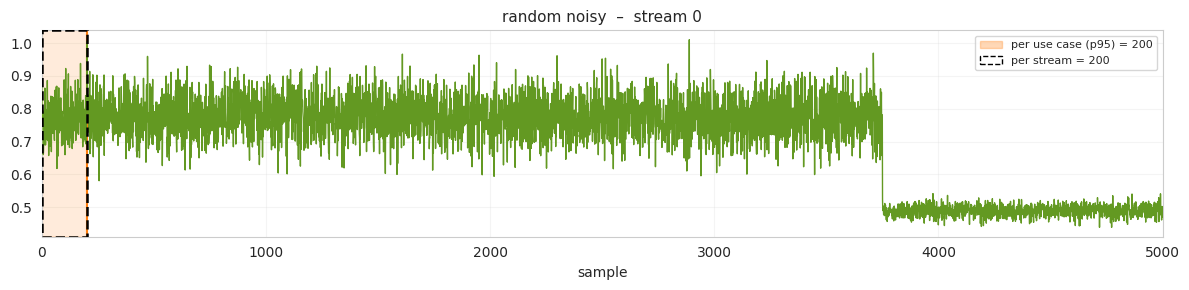

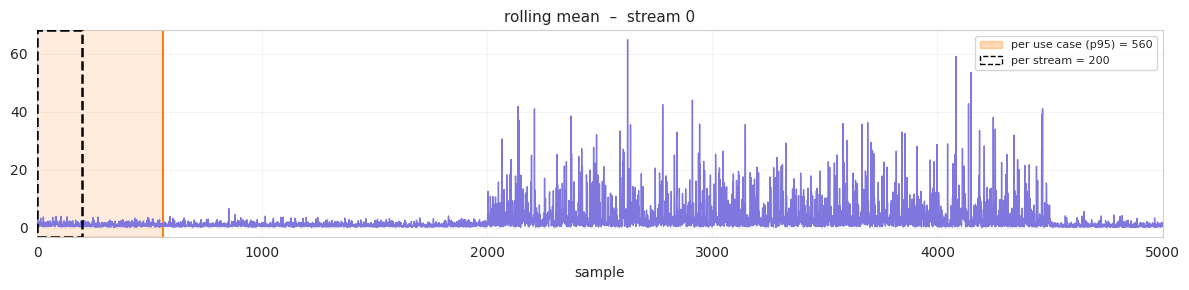

In [10]:
# ── One figure per stream, in use-case order (cropped to cut_of_stream) ──

data_streams_by_ts = {
    'AR4_linear_1':              data_streams_AR4_linear_1,
    'AR4_nonlinear_1':           data_streams_AR4_nonlinear_1,
    'random_noisy':              data_streams_random_noisy,
    'random_easy':               data_streams_random_easy,
    'rolling_mean':              data_streams_rolling_mean,
    'friedman_5_drifts':         data_streams_friedman_5_drifts,
    'friedman_2_drifts':         data_streams_friedman_2_drifts,
    'friedman_no_drifts':        data_streams_friedman_no_drifts,
    'infocom_5G_add_hour':       data_streams_infocom_5G_add_hour,
    'infocom_4G_add_hour':       data_streams_infocom_4G_add_hour,
    'infocom_5G_add_hour_trend': data_streams_infocom_5G_add_hour_trend,
    'infocom_4G_add_hour_trend': data_streams_infocom_4G_add_hour_trend,
}

# order of use cases (edit freely)
ts_names = [
    'AR4_linear_1', 'AR4_nonlinear_1',
    'friedman_no_drifts', 'friedman_2_drifts', 'friedman_5_drifts',
    'infocom_4G_add_hour', 'infocom_4G_add_hour_trend',
    'infocom_5G_add_hour', 'infocom_5G_add_hour_trend',
    'random_easy', 'random_noisy',
    'rolling_mean',
]

MAX_STREAMS = 1     # e.g. 10 to only plot the first 10 streams of each use case; None = all
FIGSIZE     = (12, 3)

def get_clean_stream(streams, i):
    s = np.array(streams[i], dtype=float)
    s = s[~np.isnan(s)]
    return s[:5000]

for ts in ts_names:
    wins      = np.array(ts_windows[ts], dtype=float)
    w_usecase = np.nanpercentile(wins, 95) if np.isfinite(wins).any() else np.nan
    color     = colors[ts]

    n_streams = len(data_streams_by_ts[ts])
    if MAX_STREAMS is not None:
        n_streams = min(n_streams, MAX_STREAMS)

    for i in range(n_streams):
        try:
            stream   = get_clean_stream(data_streams_by_ts[ts], i)
            w_stream = wins[i]

            fig, ax = plt.subplots(figsize=FIGSIZE)

            if len(stream) == 0:
                ax.set_title(f"{ts.replace('_', ' ')} – stream {i} (empty)")
                plt.show()
                continue

            ax.plot(np.arange(len(stream)), stream, '-', lw=1, color=color, zorder=3)

            y_min, y_max = stream.min(), stream.max()
            pad = 0.05 * (y_max - y_min if y_max > y_min else 1.0)
            y_lo, y_hi = y_min - pad, y_max + pad

            handles = []

            # box 1: stable window per use case (p95) – filled orange
            if np.isfinite(w_usecase):
                ax.add_patch(mpatches.Rectangle(
                    (0, y_lo), w_usecase, y_hi - y_lo,
                    facecolor='tab:orange', alpha=0.15, edgecolor='tab:orange', linewidth=1.5, zorder=1))
                ax.axvline(w_usecase, color='tab:orange', linewidth=1.5, zorder=2)
                handles.append(mpatches.Patch(facecolor='tab:orange', alpha=0.3, edgecolor='tab:orange',
                                              label=f'per use case (p95) = {w_usecase:.0f}'))

            # box 2: stable window per stream – dashed black outline (only if it exists)
            if np.isfinite(w_stream):
                ax.add_patch(mpatches.Rectangle(
                    (0, y_lo), w_stream, y_hi - y_lo,
                    facecolor='none', edgecolor='black', linestyle='--', linewidth=1.8, zorder=4))
                handles.append(mpatches.Patch(facecolor='none', edgecolor='black', linestyle='--',
                                              label=f'per stream = {w_stream:.0f}'))
            else:
                handles.append(mpatches.Patch(facecolor='none', edgecolor='none',
                                              label='per stream = n/a (no stable window)'))

            ax.set_xlim(0, len(stream))
            ax.set_ylim(y_lo, y_hi)
            ax.set_title(f"{ts.replace('_', ' ')}  –  stream {i}", fontsize=11)
            ax.set_xlabel('sample')
            ax.grid(alpha=0.2)
            ax.legend(handles=handles, loc='upper right', fontsize=8)

            plt.tight_layout()
            plt.show()

        except Exception as e:
            print(f"[{ts} / stream {i}] skipped: {type(e).__name__}: {e}")
            plt.close('all')